# Simulação

O sinal dura 4 s a fs = 1000 Hz (Δf = 0,25 Hz), com ruído gaussiano de desvio 0,1 e semente 42. A banda passante até 80 Hz inclui 40 Hz com margem. A rejeição começa antes de 200 Hz, permitindo transição de 70 Hz. Compare FIR Hamming de comprimento ímpar escolhido por validação com IIR Butterworth de ordem calculada.

Execute as células em ordem. Os dados são sintéticos; não representam medições experimentais.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from IPython.display import display
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

def espectro(x, fs, janela=None, nfft=None):
    w = np.ones(len(x)) if janela is None else janela
    X = np.fft.rfft(x*w, n=nfft)
    f = np.fft.rfftfreq(len(x) if nfft is None else nfft, 1/fs)
    A = np.abs(X)/w.sum()
    A[1:] *= 2
    if (len(x) if nfft is None else nfft) % 2 == 0:
        A[-1] /= 2
    return f, A

def plano(b, a, ax):
    # Coeficientes em potências de z^-1; completar graus para exibir polos na origem.
    grau = max(len(b), len(a))-1
    z = np.roots(np.pad(b, (0, grau+1-len(b))))
    p = np.roots(np.pad(a, (0, grau+1-len(a))))
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo unitário')
    ax.scatter(z.real, z.imag, facecolors='none', edgecolors='C0', label='Zeros')
    ax.scatter(p.real, p.imag, marker='x', color='C1', label='Polos')
    ax.set(xlabel='Parte real', ylabel='Parte imaginária', title='Plano z')
    ax.axis('equal'); ax.legend()

def analisar(b, a=(1,), fs=1000, nome='Filtro'):
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    impulso = np.r_[1., np.zeros(119)]
    h = signal.lfilter(b, a, impulso)
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    ax[0,0].stem(np.arange(len(h)), h); ax[0,0].set(title=nome+' — impulso', xlabel='n (amostras)', ylabel='h[n]')
    plano(np.asarray(b), np.asarray(a), ax[0,1])
    ax[0,2].plot(w, np.abs(H)); ax[0,2].set(title='Magnitude linear', xlabel='f (Hz)', ylabel='Ganho')
    ax[1,0].plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12))); ax[1,0].set(title='Magnitude em dB', xlabel='f (Hz)', ylabel='Ganho (dB)', ylim=(-100,5))
    fase = np.unwrap(np.angle(H))
    ax[1,1].plot(w, fase); ax[1,1].set(title='Fase', xlabel='f (Hz)', ylabel='Fase (rad)')
    gd = -np.gradient(fase, 2*np.pi*w/fs)
    gd[np.abs(H)<1e-5] = np.nan
    ax[1,2].plot(w, gd); ax[1,2].set(title='Atraso de grupo (fora dos nulos)', xlabel='f (Hz)', ylabel='Amostras')
    fig.tight_layout(); plt.show()
    print('b =', np.asarray(b)); print('a =', np.asarray(a))
    print('Polos:', np.roots(a), 'Estável causal:', np.all(np.abs(np.roots(a)) < 1))


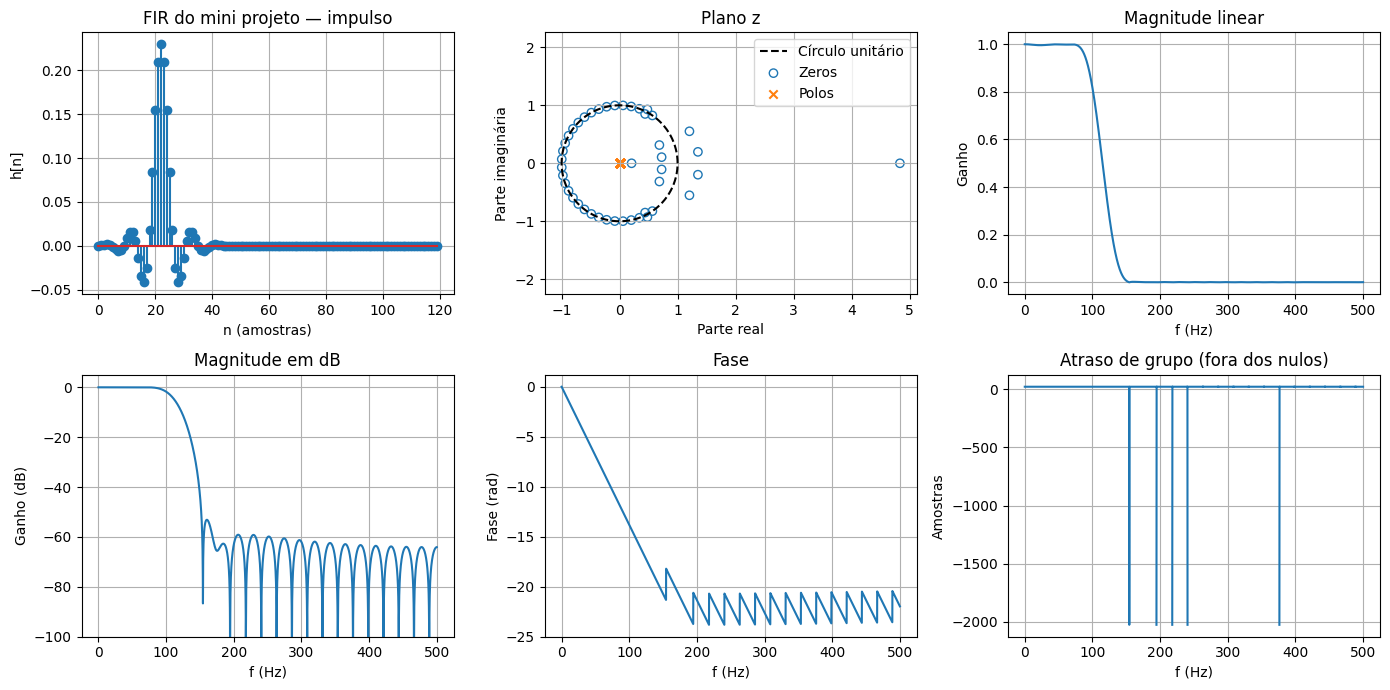

b = [-2.16441858e-04  6.52038586e-04  1.48986617e-03  1.86528200e-03
  1.14978721e-03 -1.00275082e-03 -4.00228301e-03 -6.09290780e-03
 -5.04615194e-03  3.14987484e-04  8.59880634e-03  1.55244791e-02
  1.55594495e-02  5.15537667e-03 -1.39847303e-02 -3.36738817e-02
 -4.14088139e-02 -2.56013956e-02  1.83068904e-02  8.39334270e-02
  1.54636105e-01  2.09081583e-01  2.29522557e-01  2.09081583e-01
  1.54636105e-01  8.39334270e-02  1.83068904e-02 -2.56013956e-02
 -4.14088139e-02 -3.36738817e-02 -1.39847303e-02  5.15537667e-03
  1.55594495e-02  1.55244791e-02  8.59880634e-03  3.14987484e-04
 -5.04615194e-03 -6.09290780e-03 -4.00228301e-03 -1.00275082e-03
  1.14978721e-03  1.86528200e-03  1.48986617e-03  6.52038586e-04
 -2.16441858e-04]
a = [1.]
Polos: [] Estável causal: True
FIR equação: y[n] = soma b[k]x[n-k] - soma a[k]y[n-k], a[0]=1


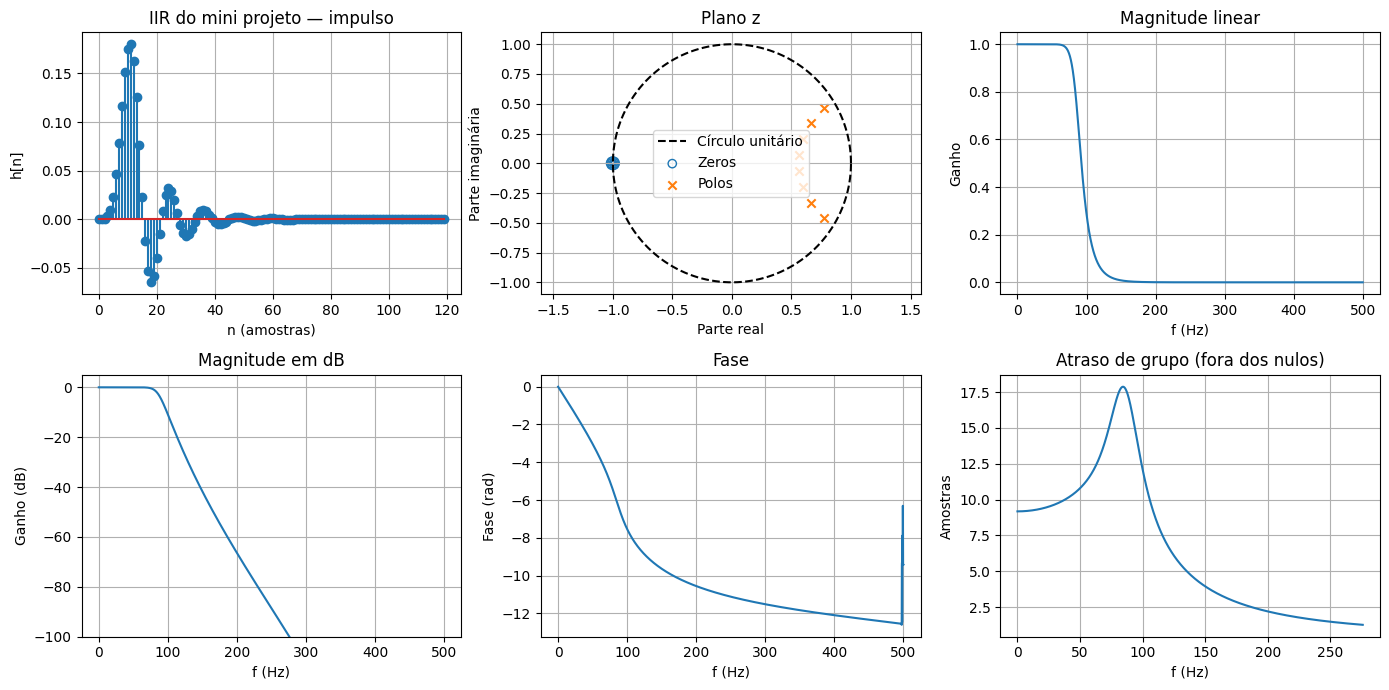

b = [8.97754728e-06 7.18203783e-05 2.51371324e-04 5.02742648e-04
 6.28428310e-04 5.02742648e-04 2.51371324e-04 7.18203783e-05
 8.97754728e-06]
a = [  1.          -5.21053433  12.22219774 -16.76747247  14.66317686
  -8.34855367   3.01616106  -0.63117624   0.05849931]
Polos: [0.77666109+0.46166593j 0.77666109-0.46166593j 0.66399355+0.33460512j
 0.66399355-0.33460512j 0.59763829+0.20123324j 0.59763829-0.20123324j
 0.56697424+0.06703805j 0.56697424-0.06703805j] Estável causal: True
IIR equação: y[n] = soma b[k]x[n-k] - soma a[k]y[n-k], a[0]=1


,0,1
Filtro,FIR,IIR
Ordem,44,8
Coeficientes (sem a0),45,17
Multiplicações/amostra,45,17
Somas/amostra,44,16
Atenuação rejeição (dB),43.326879,41.760124
Ripple (dB),0.077623,0.9975
Atraso grupo mín. (amostras),22.0,9.173531
Atraso grupo máx. (amostras),22.0,17.23056
Alinhamento (amostras),22,9


Entrada: MSE = 0.18871318922388677 SNR = 4.23167750133018 dB


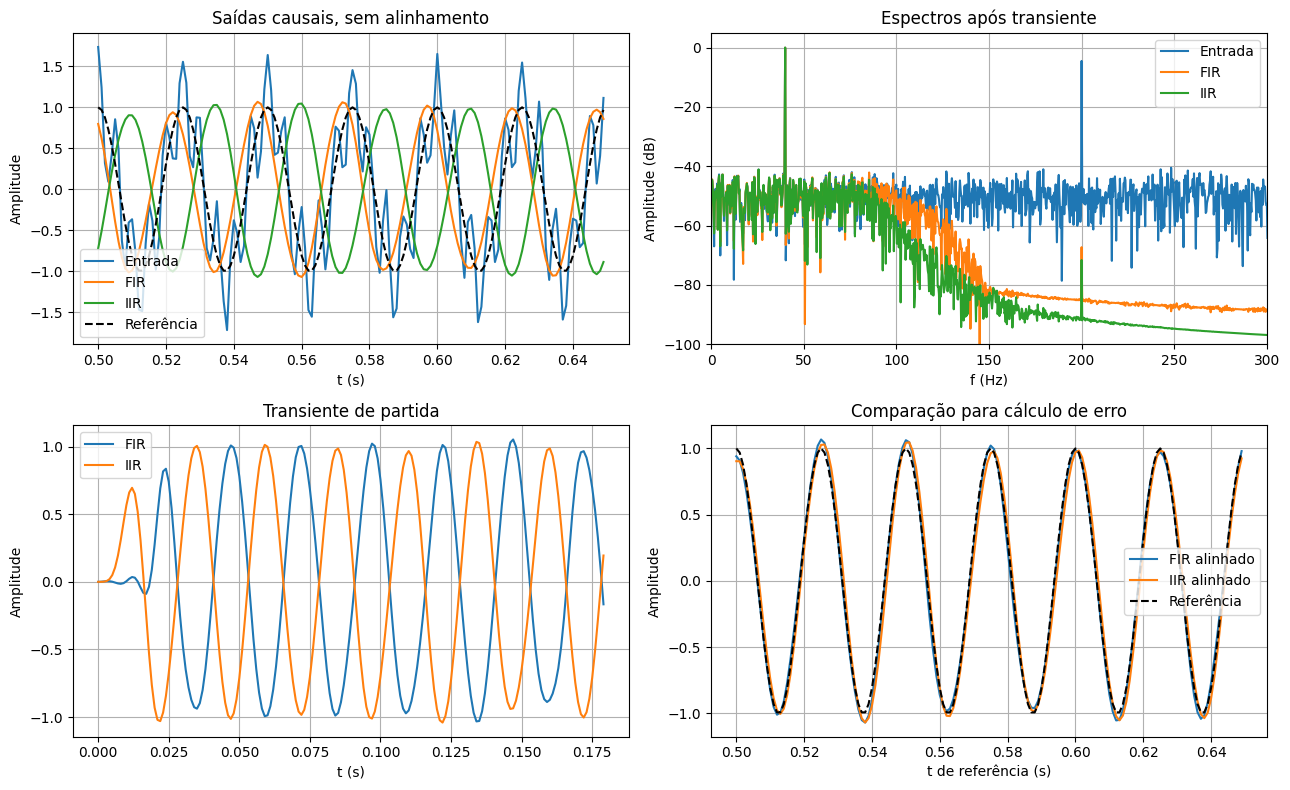

In [2]:
fs=1000; t=np.arange(4000)/fs; ref=np.cos(2*np.pi*40*t)
x=ref+.6*np.cos(2*np.pi*200*t)+np.random.default_rng(42).normal(0,.1,len(t))
for L in range(11,402,2):
    bf=signal.firwin(L,115,window='hamming',fs=fs)
    f,H=signal.freqz(bf,worN=32768,fs=fs); db=20*np.log10(np.maximum(abs(H),1e-15))
    if db[f<=80].min()>=-1 and db[f<=80].max()<=1 and db[f>=150].max()<=-40: break
else: raise RuntimeError('FIR não atende às especificações')
N,Wn=signal.buttord(80,150,1,40,fs=fs)
bi,ai=signal.butter(N,Wn,fs=fs)
sos=signal.butter(N,Wn,fs=fs,output='sos')
yf=signal.lfilter(bf,[1],x); yi=signal.sosfilt(sos,x)
# Validação espectral nas mesmas bandas, antes de medir erros no tempo.
linhas=[]
for nome,b,a,y in [('FIR',bf,np.array([1.]),yf),('IIR',bi,ai,yi)]:
    f,H=signal.freqz(b,a,worN=32768,fs=fs); db=20*np.log10(np.maximum(abs(H),1e-15)); pb=db[f<=80]; ar=-db[f>=150].max()
    assert pb.min()>=-1.001 and pb.max()<=1.001 and ar>=39.999
    assert np.all(np.abs(np.roots(a))<1)
    # Alinhamento por fase na frequência útil; não equivale a retirar a distorção de fase de banda larga.
    ww,HH=signal.freqz(b,a,worN=np.array([2*np.pi*40/fs,2*np.pi*200/fs]))
    atraso= int(round(-np.angle(HH[0])/(2*np.pi*40/fs))) if nome=='IIR' else (len(b)-1)//2
    inicio=500; fim=len(x)-100-max(atraso,0)
    alvo=ref[inicio:fim]; medido=y[inicio+atraso:fim+atraso]
    mse=np.mean((medido-alvo)**2); snr=10*np.log10(np.mean(alvo**2)/mse)
    mse_bruto=np.mean((y[inicio:fim]-alvo)**2)
    w,Ha=signal.freqz(b,a,worN=8192,fs=fs); gd=-np.gradient(np.unwrap(np.angle(Ha)),2*np.pi*w/fs)
    group=gd[w<=80]
    linhas.append([nome,max(len(b),len(a))-1,len(b)+len(a)-1,len(b)+len(a)-1,len(b)+len(a)-2,ar,pb.max()-pb.min(),group.min(),group.max(),atraso,abs(HH[0]),20*np.log10(abs(HH[1])),mse_bruto,mse,snr])
    analisar(b,a,fs,nome+' do mini projeto')
    print(nome,'equação: y[n] = soma b[k]x[n-k] - soma a[k]y[n-k], a[0]=1')
df=pd.DataFrame(linhas,columns=['Filtro','Ordem','Coeficientes (sem a0)','Multiplicações/amostra','Somas/amostra','Atenuação rejeição (dB)','Ripple (dB)','Atraso grupo mín. (amostras)','Atraso grupo máx. (amostras)','Alinhamento (amostras)','Ganho 40 Hz','Ganho 200 Hz (dB)','MSE sem alinhar','MSE alinhado','SNR alinhada (dB)'])
display(df.T)
inicio=500; fim=3800; mse0=np.mean((x[inicio:fim]-ref[inicio:fim])**2)
print('Entrada: MSE =',mse0,'SNR =',10*np.log10(np.mean(ref[inicio:fim]**2)/mse0),'dB')
fig,ax=plt.subplots(2,2,figsize=(13,8))
for nome,v in [('Entrada',x),('FIR',yf),('IIR',yi)]:
    ax[0,0].plot(t[500:650],v[500:650],label=nome)
    f,A=espectro(v[500:3500],fs); ax[0,1].plot(f,20*np.log10(np.maximum(A,1e-9)),label=nome)
ax[0,0].plot(t[500:650],ref[500:650],'k--',label='Referência')
ax[0,0].set(title='Saídas causais, sem alinhamento',xlabel='t (s)',ylabel='Amplitude')
ax[0,1].set(title='Espectros após transiente',xlabel='f (Hz)',ylabel='Amplitude (dB)',xlim=(0,300),ylim=(-100,5))
ax[1,0].plot(t[:180],yf[:180],label='FIR'); ax[1,0].plot(t[:180],yi[:180],label='IIR'); ax[1,0].set(title='Transiente de partida',xlabel='t (s)',ylabel='Amplitude')
for nome,y,atraso in [('FIR',yf,int(df.iloc[0]['Alinhamento (amostras)'])),('IIR',yi,int(df.iloc[1]['Alinhamento (amostras)']))]:
    ax[1,1].plot(t[500:650],y[500+atraso:650+atraso],label=nome+' alinhado')
ax[1,1].plot(t[500:650],ref[500:650],'k--',label='Referência'); ax[1,1].set(title='Comparação para cálculo de erro',xlabel='t de referência (s)',ylabel='Amplitude')
for a in ax.flat: a.legend()
plt.tight_layout(); plt.show()
